<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_7/dataset_pbl/tugas_praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TUGAS PRAKTIKUM**
### **Instruksi Umum:**

Anda akan menggunakan dataset "Sleep Health and Lifestyle". Pastikan Anda telah mengunduh dataset ini.

Gunakan bahasa pemrograman Python dan library yang sesuai seperti NumPy, Pandas, Matplotlib dan Scikit-Learn untuk melakukan analisis regresi dan SVR.

### **Tugas 1: Multiple Linear Regression**

1. Identifikasi variabel-variabel yang akan digunakan sebagai variabel bebas (fitur) dan variabel target (biaya medis personal).

2. Bagi dataset menjadi data latih (train) dan data uji (test) dengan proporsi yang sesuai.

3. Lakukan feature scaling jika diperlukan.

4. Buat model multiple linear regression menggunakan Scikit-Learn.

5. Latih model pada data latih dan lakukan prediksi pada data uji.

6. Evaluasi model dengan menghitung metrik seperti R-squared, MSE, dan MAE. Tampilkan hasil evaluasi.

### **Catatan Tambahan:**

1. Pastikan untuk memberikan penjelasan singkat tentang dataset yang digunakan, termasuk deskripsi variabel-variabel yang relevan.

2. Tampilkan visualisasi data yang relevan seperti scatter plot atau grafik lainnya jika diperlukan untuk pemahaman yang lebih baik.

3. Analisis hasil yang Anda dapatkan dalam tugas praktikum Anda.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# Hapus Person ID karena hanya berupa nomor urut
df_clean = df.drop(columns=['Person ID'], errors='ignore')

# Tangani nilai kosong pada kolom Sleep Disorder jika terbaca sebagai NaN
if 'Sleep Disorder' in df_clean.columns:
    df_clean['Sleep Disorder'] = df_clean['Sleep Disorder'].fillna('None')

# Pecah Blood Pressure (misal "126/83") menjadi dua fitur numerik terpisah
if 'Blood Pressure' in df_clean.columns:
    bp_split = df_clean['Blood Pressure'].str.split('/', expand=True)
    df_clean['Systolic_BP'] = pd.to_numeric(bp_split[0])
    df_clean['Diastolic_BP'] = pd.to_numeric(bp_split[1])
    df_clean = df_clean.drop(columns=['Blood Pressure'])

# One-hot encoding untuk variabel kategorikal
df_encoded = pd.get_dummies(df_clean, drop_first=True)

# Identifikasi Variabel Bebas (X) dan Target (y)
X = df_encoded.drop('Quality of Sleep', axis=1)
y = df_encoded['Quality of Sleep']

In [3]:
# Pembagian Dataset (Train dan Test dengan proporsi 80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
# Membuat Model Multiple Linear Regression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [6]:
# Melatih Model dan Melakukan Prediksi
y_pred = model.predict(X_test_scaled)

In [7]:
# Evaluasi Model
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"R-squared : {r2:.4f}")
print(f"MSE       : {mse:.4f}")
print(f"RMSE      : {rmse:.4f}")
print(f"MAE       : {mae:.4f}")

R-squared : 0.9661
MSE       : 0.0511
RMSE      : 0.2261
MAE       : 0.1195


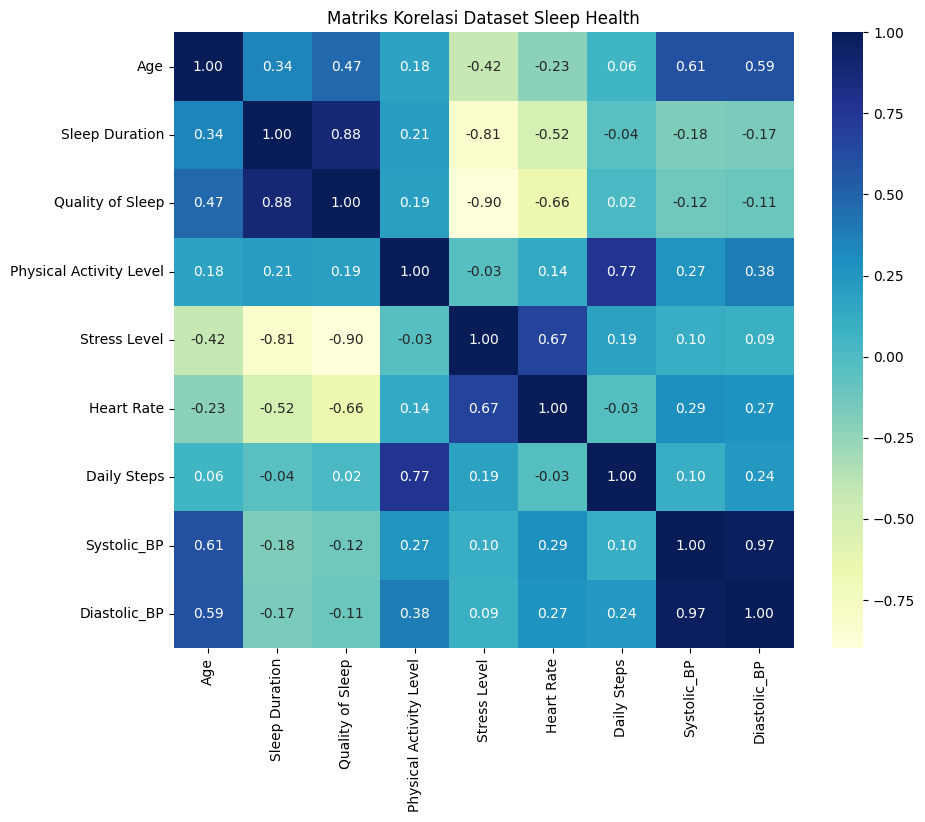

In [8]:
# Heatmap Korelasi Fitur Numerik Utama
numeric_cols = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic_BP', 'Diastolic_BP']
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[numeric_cols].corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Matriks Korelasi Dataset Sleep Health')
plt.show()

### **Catatan Tambahan**

1. Berikut adalah deskripsi variabel yang relevan dalam dataset **Sleep Health and Lifestyle** yang digunakan:
   * **Gender**: Jenis kelamin individu (Pria atau Wanita).
   * **Age**: Usia individu dalam tahun.
   * **Occupation**: Jenis pekerjaan atau profesi individu.
   * **Sleep Duration**: Lama waktu tidur harian dalam satuan jam.
   * **Physical Activity Level**: Tingkat aktivitas fisik harian dalam satuan menit per hari.
   * **Stress Level**: Tingkat stres subjektif pada skala 1 hingga 10.
   * **BMI Category**: Kategori Indeks Massa Tubuh (*Normal*, *Normal Weight*, *Overweight*, *Obese*).
   * **Blood Pressure**: Tekanan darah harian (dipecah menjadi fitur **Systolic_BP** dan **Diastolic_BP**).
   * **Heart Rate**: Detak jantung istirahat dalam denyut per menit (bpm).
   * **Daily Steps**: Jumlah langkah kaki harian.
   * **Sleep Disorder**: Riwayat gangguan tidur (*None*, *Insomnia*, atau *Sleep Apnea*).
   * **Quality of Sleep**: Skor kualitas tidur subjektif pada skala 1 hingga 10 sebagai **variabel target**.

2. Tampilan visualisasi data yang relevan berupa matriks korelasi (*heatmap*) dan *scatter plot* disajikan untuk memperjelas hubungan antarvariabel.

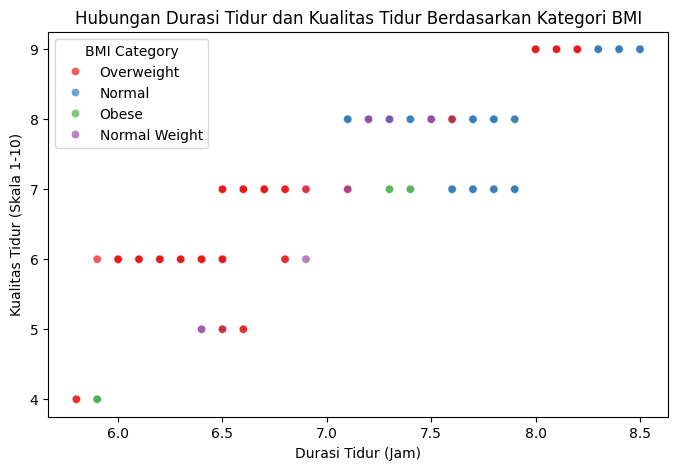

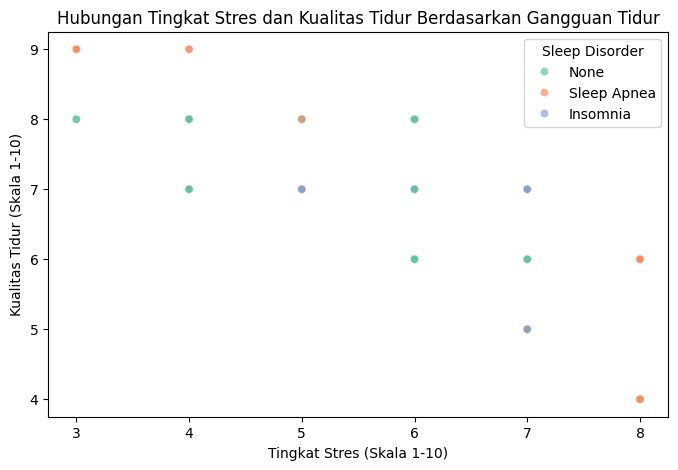

In [9]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# Scatter Plot 1: Hubungan Durasi Tidur dan Kualitas Tidur Berdasarkan Kategori BMI
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='Sleep Duration', y='Quality of Sleep', hue='BMI Category', palette='Set1', alpha=0.7)
plt.title('Hubungan Durasi Tidur dan Kualitas Tidur Berdasarkan Kategori BMI')
plt.xlabel('Durasi Tidur (Jam)')
plt.ylabel('Kualitas Tidur (Skala 1-10)')
plt.show()

# Scatter Plot 2: Hubungan Tingkat Stres dan Kualitas Tidur Berdasarkan Gangguan Tidur
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='Stress Level', y='Quality of Sleep', hue='Sleep Disorder', palette='Set2', alpha=0.7)
plt.title('Hubungan Tingkat Stres dan Kualitas Tidur Berdasarkan Gangguan Tidur')
plt.xlabel('Tingkat Stres (Skala 1-10)')
plt.ylabel('Kualitas Tidur (Skala 1-10)')
plt.show()

3. **Analisis hasil praktik regresi linier berganda pada dataset Sleep Health and Lifestyle:**
   * **Evaluasi Kinerja Model:**
     * **Skor R-squared sebesar 0,9661**: Model regresi linier berganda mampu menjelaskan **96,61%** variasi nilai kualitas tidur dalam dataset, menunjukkan tingkat kecocokan model yang sangat tinggi.
     * **Nilai Error (MSE, RMSE, dan MAE)**: Nilai **MSE sebesar 0,0511**, **RMSE sebesar 0,2261**, dan **MAE sebesar 0,1195** mencerminkan rata-rata selisih prediksi skor kualitas tidur yang sangat kecil dari nilai aktualnya (pada rentang skala 1–10).
   * **Pola Hubungan Variabel:**
     * **Pengaruh Durasi Tidur**: Berdasarkan matriks korelasi dan *scatter plot*, durasi tidur memiliki korelasi positif yang sangat kuat terhadap kualitas tidur; semakin lama durasi tidur, semakin tinggi skor kualitas tidur yang diperoleh.
     * **Pengaruh Tingkat Stres dan Gangguan Tidur**: Tingkat stres memiliki korelasi negatif yang kuat terhadap kualitas tidur, di mana individu dengan tingkat stres tinggi serta riwayat gangguan tidur (*Insomnia* maupun *Sleep Apnea*) cenderung memiliki skor kualitas tidur yang jauh lebih rendah.